# handle Mixed_variables 

In [1]:
import pandas as pd 
import numpy as np 


df = pd.read_csv(r'E:\MACHINE_LEARNING\DAY_33\DAtasets\titanic.csv')

In [2]:
df.head(10)

,Cabin,Ticket,number,Survived
0,NaN,A/5 21171,5,0
1,C85,PC 17599,3,1
2,NaN,STON/O2. 3101282,6,1
3,C123,113803,3,1
4,NaN,373450,A,0
5,NaN,330877,2,0
6,E46,17463,2,0
7,NaN,349909,5,0
8,NaN,347742,1,1
9,NaN,237736,A,1


In [3]:
df['number'].unique()

<StringArray>
['5', '3', '6', 'A', '2', '1', '4']
Length: 7, dtype: str

In [4]:
# now when you have the data that holds both the number and numerical but in differnet row  then actually

df['number_numerical'] = pd.to_numeric(df['number'] , errors= 'coerce', downcast= 'integer')



In [5]:
# extract catogirical part 

df['number_categorical'] = np.where(df['number_numerical'].isnull() , df['number'] , np.nan)

df.head()

,Cabin,Ticket,number,Survived,number_numerical,number_categorical
0,NaN,A/5 21171,5,0,5.0,NaN
1,C85,PC 17599,3,1,3.0,NaN
2,NaN,STON/O2. 3101282,6,1,6.0,NaN
3,C123,113803,3,1,3.0,NaN
4,NaN,373450,A,0,NaN,A


In [6]:
df['Cabin'].unique()


df['cabin_num'] = df['Cabin'].str.extract('(\d+)') 

df['cabin_cat'] = df['Cabin'].str[0]


<>:4: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:4: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
C:\Users\saumi\AppData\Local\Temp\ipykernel_21712\1567591655.py:4: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
  df['cabin_num'] = df['Cabin'].str.extract('(\d+)')


In [7]:
df.head()

,Cabin,Ticket,number,Survived,number_numerical,number_categorical,cabin_num,cabin_cat
0,NaN,A/5 21171,5,0,5.0,NaN,NaN,NaN
1,C85,PC 17599,3,1,3.0,NaN,85,C
2,NaN,STON/O2. 3101282,6,1,6.0,NaN,NaN,NaN
3,C123,113803,3,1,3.0,NaN,123,C
4,NaN,373450,A,0,NaN,A,NaN,NaN


<Axes: xlabel='cabin_cat'>

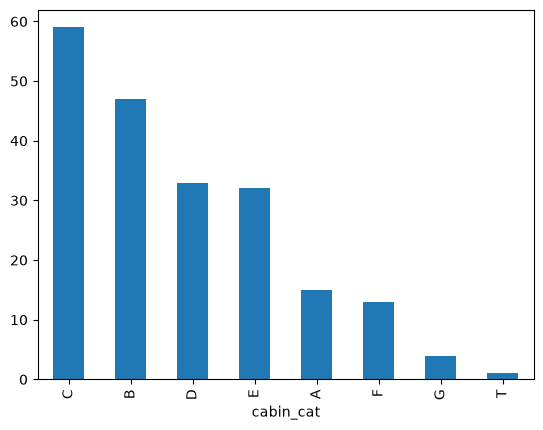

In [8]:
df['cabin_cat'].value_counts().plot(kind = 'bar')

In [9]:
# extract the last bit of ticket as number
df['ticket_num'] = df['Ticket'].apply(lambda s: s.split()[-1])
df['ticket_num'] = pd.to_numeric(df['ticket_num'],
                                   errors='coerce',
                                   downcast='integer')

# extract the first part of ticket as category
df['ticket_cat'] = df['Ticket'].apply(lambda s: s.split()[0])
df['ticket_cat'] = np.where(df['ticket_cat'].str.isdigit(), np.nan,
                              df['ticket_cat'])


<Axes: xlabel='ticket_num'>

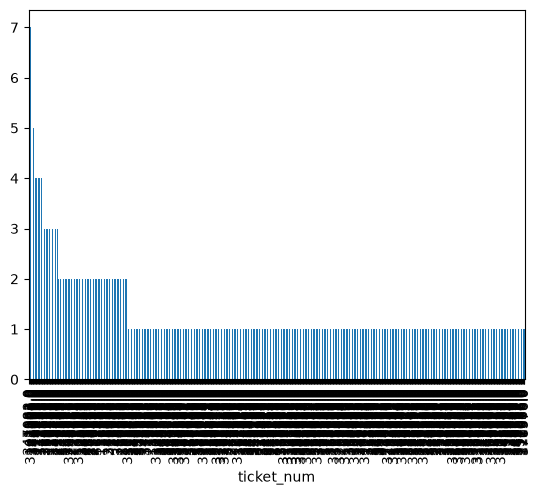

In [11]:
df['ticket_num'].value_counts().plot(kind = 'bar')